In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'core').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.figsize': (7, 4)})
FIG = ROOT / 'results' / 'figures'; DATA = ROOT / 'results' / 'data'

# 02 — Inside the Theorem-1 LP: what does the optimal strategy-proof mechanism look like, and where is it tight?

The paper's Theorem 1 is computer-assisted: an LP over all strategy-proof mechanisms on the type
grid $\{j/N\}$. The authors note (footnote 7) that a dual certificate would make the bound
human-verifiable, but "it does not seem to shed much light". This notebook looks at what the
LP *does* say:

1. the shape of the optimal mechanism $m_1(x,y)$ (agent 1's expected share of item 1);
2. which type profiles are binding (carry dual weight) — it is a one-dimensional family, not the whole triangle;
3. **small certificates**: restricting the type space to a handful of well-chosen types already
   gives an upper bound close to the full LP. Those tiny LPs can be checked by hand (or by any LP
   solver in milliseconds), which addresses the "human-verifiable" caveat in a practical way.

Reminder of the LP (`core/lp.py`): variables $m_1(j,k), m_2(j,k)\in[0,1]$; strategy-proofness as
adjacent-type constraints (equivalent to the full set because utilities are affine in the type);
competitiveness $W(j,k)\ge\alpha\,\mathrm{OPT}(j,k)$; maximise $\alpha$.

In [2]:
from core import lp, lip
import json
opt = json.loads((DATA / "lip_alpha_opt.json").read_text())
N = 50
r = lp.solve_sp_lp(N, symmetric=True)
g = np.arange(N + 1) / N
print(f"LP value at N={N}: {r.alpha:.6f}  (paper: 0.841);  binding profiles: {int(r.binding.sum())} of {(N+1)**2}")

LP value at N=50: 0.841225  (paper: 0.841);  binding profiles: 48 of 2601


## 1. The optimal mechanism on the grid

Left: $m_1(x,y)$, agent 1's expected share of item 1 when she reports $x$ and agent 2 reports $y$.
Right: the same for the best LIP mechanism, for comparison. The LP mechanism is *not* unique (the
LP has many optimal vertices), but the one HiGHS returns is already informative: it looks like a
smoothed dictatorship — the share rises with $x$ and falls with $y$, and the "all-in" plateaus
of Claim 5 are visible.

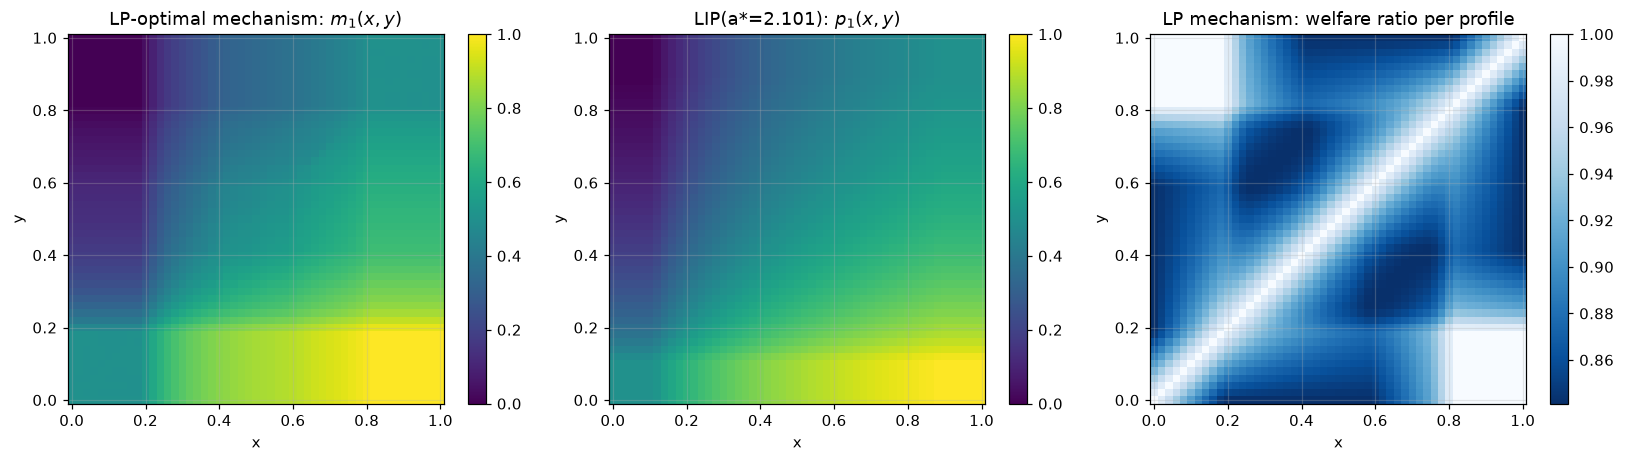

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
X, Y = np.meshgrid(g, g, indexing="ij")
im = ax[0].pcolormesh(X, Y, r.m1, cmap="viridis", vmin=0, vmax=1, shading="nearest"); plt.colorbar(im, ax=ax[0])
ax[0].set(title="LP-optimal mechanism: $m_1(x,y)$", xlabel="x", ylabel="y")
p1, _ = lip.expected_shares(X, Y, opt["a_star"])
im = ax[1].pcolormesh(X, Y, p1, cmap="viridis", vmin=0, vmax=1, shading="nearest"); plt.colorbar(im, ax=ax[1])
ax[1].set(title=f"LIP(a*={opt['a_star']:.3f}): $p_1(x,y)$", xlabel="x", ylabel="y")
im = ax[2].pcolormesh(X, Y, r.ratio, cmap="Blues_r", shading="nearest"); plt.colorbar(im, ax=ax[2])
ax[2].set(title="LP mechanism: welfare ratio per profile", xlabel="x", ylabel="y")
plt.tight_layout(); plt.savefig(FIG / "02_lp_mechanism.png"); plt.show()

## 2. Binding profiles

Dual multipliers $\lambda_{jk}\ge0$ of the competitiveness constraints satisfy
$\sum_{jk}\lambda_{jk}\mathrm{OPT}_{jk}=1$; a profile with $\lambda_{jk}>0$ is one where the
optimal mechanism's ratio is exactly $\alpha$ *and* which "pays" for the bound. Only about $N$ of
the $(N+1)^2$ profiles are binding, and they lie on a curve.

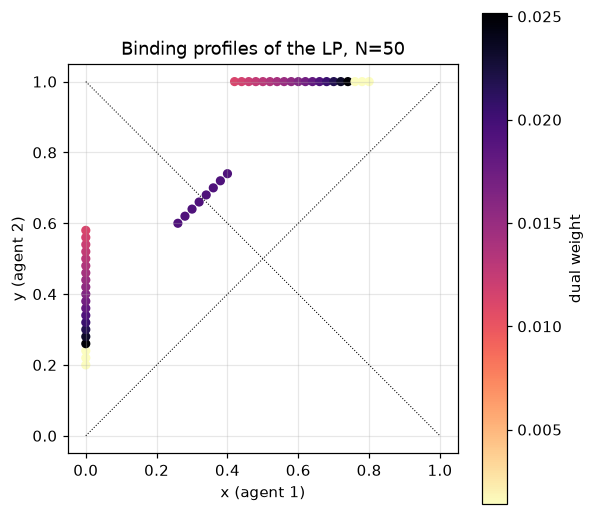

binding profiles (x, y, weight), heaviest first:
   x    y  weight
0.74 1.00  0.0251
0.00 0.26  0.0251
0.00 0.28  0.0233
0.72 1.00  0.0233
0.00 0.30  0.0218
0.70 1.00  0.0218
0.00 0.32  0.0204
0.68 1.00  0.0204
0.66 1.00  0.0192
0.40 0.74  0.0192
0.28 0.62  0.0192
0.32 0.66  0.0192


In [4]:
fig, ax = plt.subplots(figsize=(5.5, 5))
jj, kk = np.nonzero(r.binding)
sc = ax.scatter(g[jj], g[kk], c=r.dual_welfare[jj, kk], cmap="magma_r", s=25)
plt.colorbar(sc, label="dual weight")
ax.plot([0, 1], [0, 1], "k:", lw=0.7); ax.plot([0, 1], [1, 0], "k:", lw=0.7)
ax.set(xlabel="x (agent 1)", ylabel="y (agent 2)", title=f"Binding profiles of the LP, N={N}", aspect="equal")
plt.tight_layout(); plt.savefig(FIG / "02_binding_profiles.png"); plt.show()
print("binding profiles (x, y, weight), heaviest first:")
order = np.argsort(-r.dual_welfare[jj, kk])[:12]
print(pd.DataFrame({"x": g[jj][order], "y": g[kk][order], "weight": r.dual_welfare[jj, kk][order]}).round(4).to_string(index=False))

## 3. Small certificates: how few types are needed for a good upper bound?

Any subset $T\subset[0,1]$ of types gives a valid upper bound (the mechanism only has to be
strategy-proof and competitive on $T\times T$). Below we grow a type set greedily: start from
$\{0,\tfrac12,1\}$ and repeatedly add the grid type that lowers the LP value the most. The
resulting LPs have a few dozen variables.

In [5]:
import time
cand = np.arange(0, 1.0001, 0.02)
Tset = [0.0, 0.5, 1.0]
hist = []
t0 = time.time()
for step in range(12):
    best = None
    for c in cand:
        if any(abs(c - t) < 1e-9 for t in Tset):
            continue
        val = lp.solve_sp_lp(0, types=sorted(Tset + [c])).alpha
        if best is None or val < best[0]:
            best = (val, c)
    Tset = sorted(Tset + [best[1]])
    hist.append({"n_types": len(Tset), "added": best[1], "LP value": best[0], "types": [round(t, 2) for t in Tset]})
    print(hist[-1], flush=True)
print(f"{time.time()-t0:.0f}s")
hist_df = pd.DataFrame(hist)

{'n_types': 4, 'added': np.float64(0.22), 'LP value': 0.9082787373436569, 'types': [0.0, np.float64(0.22), 0.5, 1.0]}


{'n_types': 5, 'added': np.float64(0.76), 'LP value': 0.8956033676333022, 'types': [0.0, np.float64(0.22), 0.5, np.float64(0.76), 1.0]}


{'n_types': 6, 'added': np.float64(0.34), 'LP value': 0.8867330925364442, 'types': [0.0, np.float64(0.22), np.float64(0.34), 0.5, np.float64(0.76), 1.0]}


{'n_types': 7, 'added': np.float64(0.64), 'LP value': 0.8792349063016077, 'types': [0.0, np.float64(0.22), np.float64(0.34), 0.5, np.float64(0.64), np.float64(0.76), 1.0]}


{'n_types': 8, 'added': np.float64(0.86), 'LP value': 0.8734055281350739, 'types': [0.0, np.float64(0.22), np.float64(0.34), 0.5, np.float64(0.64), np.float64(0.76), np.float64(0.86), 1.0]}


...

{'n_types': 12, 'added': np.float64(0.7000000000000001), 'LP value': 0.860789324015034, 'types': [0.0, np.float64(0.12), np.float64(0.22), np.float64(0.28), np.float64(0.34), np.float64(0.4), 0.5, np.float64(0.64), np.float64(0.7), np.float64(0.76), np.float64(0.86), 1.0]}


{'n_types': 13, 'added': np.float64(0.58), 'LP value': 0.8583695387274669, 'types': [0.0, np.float64(0.12), np.float64(0.22), np.float64(0.28), np.float64(0.34), np.float64(0.4), 0.5, np.float64(0.58), np.float64(0.64), np.float64(0.7), np.float64(0.76), np.float64(0.86), 1.0]}


{'n_types': 14, 'added': np.float64(0.8), 'LP value': 0.85685909928264, 'types': [0.0, np.float64(0.12), np.float64(0.22), np.float64(0.28), np.float64(0.34), np.float64(0.4), 0.5, np.float64(0.58), np.float64(0.64), np.float64(0.7), np.float64(0.76), np.float64(0.8), np.float64(0.86), 1.0]}


{'n_types': 15, 'added': np.float64(0.92), 'LP value': 0.8556235441134685, 'types': [0.0, np.float64(0.12), np.float64(0.22), np.float64(0.28), np.float64(0.34), np.float64(0.4), 0.5, np.float64(0.58), np.float64(0.64), np.float64(0.7), np.float64(0.76), np.float64(0.8), np.float64(0.86), np.float64(0.92), 1.0]}


8s


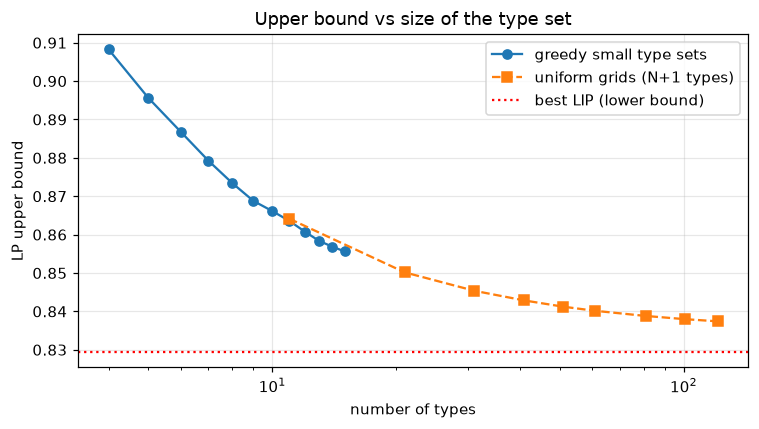

,n_types,added,LP value,types
0,4,0.22,0.908279,"[0.0, 0.22, 0.5, 1.0]"
1,5,0.76,0.895603,"[0.0, 0.22, 0.5, 0.76, 1.0]"
2,6,0.34,0.886733,"[0.0, 0.22, 0.34, 0.5, 0.76, 1.0]"
3,7,0.64,0.879235,"[0.0, 0.22, 0.34, 0.5, 0.64, 0.76, 1.0]"
4,8,0.86,0.873406,"[0.0, 0.22, 0.34, 0.5, 0.64, 0.76, 0.86, 1.0]"
5,9,0.12,0.868784,"[0.0, 0.12, 0.22, 0.34, 0.5, 0.64, 0.76, 0.86,..."
6,10,0.28,0.866145,"[0.0, 0.12, 0.22, 0.28, 0.34, 0.5, 0.64, 0.76,..."
7,11,0.40,0.863591,"[0.0, 0.12, 0.22, 0.28, 0.34, 0.4, 0.5, 0.64, ..."
8,12,0.70,0.860789,"[0.0, 0.12, 0.22, 0.28, 0.34, 0.4, 0.5, 0.64, ..."
9,13,0.58,0.858370,"[0.0, 0.12, 0.22, 0.28, 0.34, 0.4, 0.5, 0.58, ..."


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist_df.n_types, hist_df["LP value"], "o-", label="greedy small type sets")
conv = pd.read_csv(DATA / "lp_convergence_eps0.csv")
ax.plot(conv.N + 1, conv.alpha, "s--", label="uniform grids (N+1 types)")
ax.axhline(opt["alpha_upper"], c="r", ls=":", label="best LIP (lower bound)")
ax.set(xscale="log", xlabel="number of types", ylabel="LP upper bound", title="Upper bound vs size of the type set"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "02_small_certificates.png"); plt.show()
hist_df

So a dozen hand-picked types already beat the paper's 51-type grid, and the greedy sets have
a recognisable structure: types cluster around the Claim-5 regime switches ($\approx0.12$,
$\approx0.88$), near $0.4/0.6$ (the edge worst case of LIP) and at the extremes. A
human-checkable certificate is therefore realistic: the LP with ~8 types has ~130 variables and
its dual can be printed in full.

## 4. A fully explicit certificate for a small type set

For the record, here is the dual of the smallest interesting instance in closed-ish form: the
positive multipliers (rounded) on the competitiveness and incentive constraints. Anyone can
verify $\alpha^\ast$ for this type set by checking that the weighted sum of these constraints
yields $\alpha\le$ value.

In [7]:
small = hist[4]["types"]        # 8 types
rs = lp.solve_sp_lp(0, types=small)
print("types:", small, "\nLP value:", round(rs.alpha, 6))
jj, kk = np.nonzero(rs.binding)
print(pd.DataFrame({"x": np.array(small)[jj], "y": np.array(small)[kk], "lambda": rs.dual_welfare[jj, kk]}).round(5).to_string(index=False))
print("check sum lambda*OPT =", round(float(np.sum(rs.dual_welfare * rs.opt)), 6))

types: [0.0, np.float64(0.22), np.float64(0.34), 0.5, np.float64(0.64), np.float64(0.76), np.float64(0.86), 1.0] 
LP value: 0.873406
   x    y  lambda
0.00 0.22 0.06404
0.00 0.34 0.06459
0.00 0.50 0.03605
0.22 0.00 0.06404
0.22 0.50 0.00425
0.22 0.64 0.03921
0.22 0.76 0.00213
0.34 0.00 0.06459
0.34 0.76 0.02994
0.50 0.00 0.03605
0.50 0.22 0.00425
0.50 0.86 0.01294
0.50 1.00 0.02422
0.64 0.22 0.03921
0.64 1.00 0.04076
0.76 0.22 0.00213
0.76 0.34 0.02994
0.76 1.00 0.05240
0.86 0.50 0.01294
1.00 0.50 0.02422
1.00 0.64 0.04076
1.00 0.76 0.05240
check sum lambda*OPT = 1.0


## Summary

* The LP-optimal mechanism looks like a smoothed dictatorship with LIP-like plateaus.
* Binding profiles form a one-dimensional family; the heavy ones sit on the edge $y=0$ / $x=1$
  and near the anti-diagonal — the same two branches that govern LIP's worst case (notebook 01).
* Small, explicit type sets give upper bounds close to the large-grid LP, which is the practical
  answer to the paper's "no human-verifiable proof" caveat.